In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
! unzip '/content/drive/MyDrive/lung/dataset/lung_colon_image_set.zip'

Streaming output truncated to the last 5000 lines.
  inflating: lung_colon_image_set/Train and Validation Set/lung_n/lungn55.jpeg  
  inflating: lung_colon_image_set/Train and Validation Set/lung_n/lungn550.jpeg  
  inflating: lung_colon_image_set/Train and Validation Set/lung_n/lungn551.jpeg  
  inflating: lung_colon_image_set/Train and Validation Set/lung_n/lungn552.jpeg  
  inflating: lung_colon_image_set/Train and Validation Set/lung_n/lungn553.jpeg  
  inflating: lung_colon_image_set/Train and Validation Set/lung_n/lungn554.jpeg  
  inflating: lung_colon_image_set/Train and Validation Set/lung_n/lungn555.jpeg  
  inflating: lung_colon_image_set/Train and Validation Set/lung_n/lungn556.jpeg  
  inflating: lung_colon_image_set/Train and Validation Set/lung_n/lungn557.jpeg  
  inflating: lung_colon_image_set/Train and Validation Set/lung_n/lungn558.jpeg  
  inflating: lung_colon_image_set/Train and Validation Set/lung_n/lungn559.jpeg  
  inflating: lung_colon_image_set/Train and Vali

In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm
import gc

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms as transforms
import torchvision.models as models

In [5]:
# Step 2: Custom Dataset Class
class LungDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = Image.open(self.image_paths[idx]).convert('RGB')
        if self.transform:
            image = self.transform(image)
        label = self.labels[idx]
        return image, label

# Step 3: Define Classes & Paths
classes = ['colon_aca', 'colon_n', 'lung_aca', 'lung_n', 'lung_scc']  # ✅ Updated with lung_scc
train_val_dir = "/content/lung_colon_image_set/Train and Validation Set"
test_dir = "/content/lung_colon_image_set/Test Set"

# Step 4: Load Train+Val Image Paths
image_paths, labels = [], []
for class_name in classes:
    class_dir = os.path.join(train_val_dir, class_name)
    for img_name in os.listdir(class_dir):
        image_paths.append(os.path.join(class_dir, img_name))
        labels.append(class_name)

# Encode labels
le = LabelEncoder()
labels_encoded = le.fit_transform(labels)

# Step 5: Train-Validation Split
train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths, labels_encoded, test_size=0.2, stratify=labels_encoded, random_state=42
)

# Step 6: Load Test Set
test_paths, test_labels = [], []
for class_name in classes:
    class_dir = os.path.join(test_dir, class_name)
    for img_name in os.listdir(class_dir):
        test_paths.append(os.path.join(class_dir, img_name))
        test_labels.append(class_name)

test_labels = le.transform(test_labels)

# Step 7: Transforms
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

# Step 8: Datasets & Loaders
train_dataset = LungDataset(train_paths, train_labels, transform=train_transform)
val_dataset = LungDataset(val_paths, val_labels, transform=val_test_transform)
test_dataset = LungDataset(test_paths, test_labels, transform=val_test_transform)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False, pin_memory=True)


In [6]:
# Step 9: Model Setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = models.resnet18(pretrained=True)
model.fc = nn.Linear(model.fc.in_features, len(classes))
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# Step 10: Training Function (with Validation & Best Model Saving)
def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=10):
    best_acc = 0.0
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        # ---- Training ----
        model.train()
        train_loss, correct, total = 0.0, 0, 0
        for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]"):
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            _, preds = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (preds == labels).sum().item()

        train_acc = correct / total
        avg_train_loss = train_loss / len(train_loader)

        # ---- Validation ----
        model.eval()
        val_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in tqdm(val_loader, desc=f"Epoch {epoch+1}/{epochs} [Val]"):
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                val_loss += loss.item()
                _, preds = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (preds == labels).sum().item()

        val_acc = correct / total
        avg_val_loss = val_loss / len(val_loader)

        # Save history
        history["train_loss"].append(avg_train_loss)
        history["val_loss"].append(avg_val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"Epoch {epoch+1}/{epochs} - "
              f"Train Loss: {avg_train_loss:.4f}, Train Acc: {train_acc:.4f} - "
              f"Val Loss: {avg_val_loss:.4f}, Val Acc: {val_acc:.4f}")

        # Save best model
        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), "best_model.pth")
            print("✅ Best model saved!")

    return history

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 71.0MB/s]


In [ ]:
# Step 11: Train the Model
history = train_model(model, train_loader, val_loader, criterion, optimizer, epochs=15)

Epoch 1/15 [Val]: 100%|██████████| 282/282 [00:42<00:00,  6.62it/s]


Epoch 1/15 - Train Loss: 0.1687, Train Acc: 0.9362 - Val Loss: 0.0328, Val Acc: 0.9896
✅ Best model saved!


Epoch 2/15 [Val]: 100%|██████████| 282/282 [00:41<00:00,  6.76it/s]


Epoch 2/15 - Train Loss: 0.0935, Train Acc: 0.9655 - Val Loss: 0.0338, Val Acc: 0.9896


Epoch 3/15 [Val]: 100%|██████████| 282/282 [00:41<00:00,  6.78it/s]


Epoch 3/15 - Train Loss: 0.0761, Train Acc: 0.9719 - Val Loss: 0.0285, Val Acc: 0.9909
✅ Best model saved!


... (20 outputs left out)

Epoch 14/15 [Val]: 100%|██████████| 282/282 [00:41<00:00,  6.82it/s]


Epoch 14/15 - Train Loss: 0.0345, Train Acc: 0.9878 - Val Loss: 0.0060, Val Acc: 0.9973


Epoch 15/15 [Val]: 100%|██████████| 282/282 [00:41<00:00,  6.73it/s]

Epoch 15/15 - Train Loss: 0.0345, Train Acc: 0.9879 - Val Loss: 0.0075, Val Acc: 0.9976


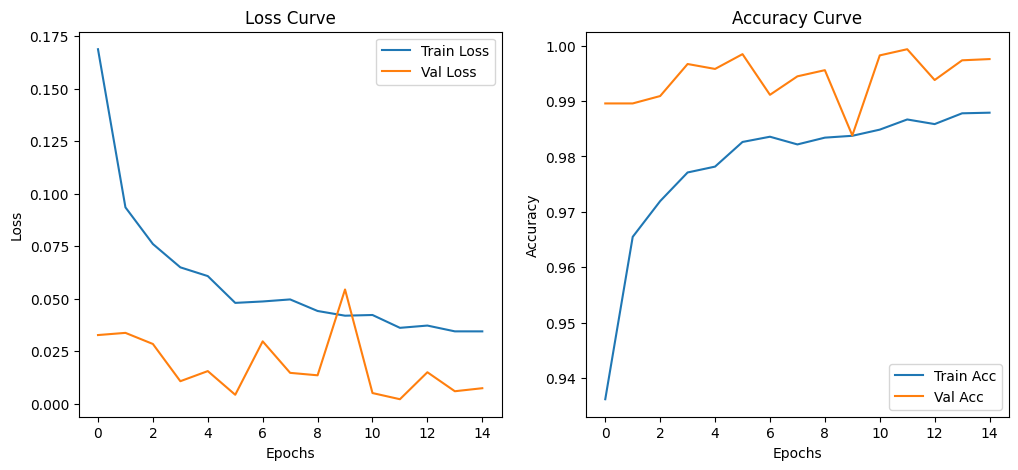

✅ Test Accuracy: 1.0
✅ Classification Report:
               precision    recall  f1-score   support

   colon_aca       1.00      1.00      1.00       500
     colon_n       1.00      1.00      1.00       500
    lung_aca       1.00      1.00      1.00       500
      lung_n       1.00      1.00      1.00       500
    lung_scc       1.00      1.00      1.00       499

    accuracy                           1.00      2499
   macro avg       1.00      1.00      1.00      2499
weighted avg       1.00      1.00      1.00      2499



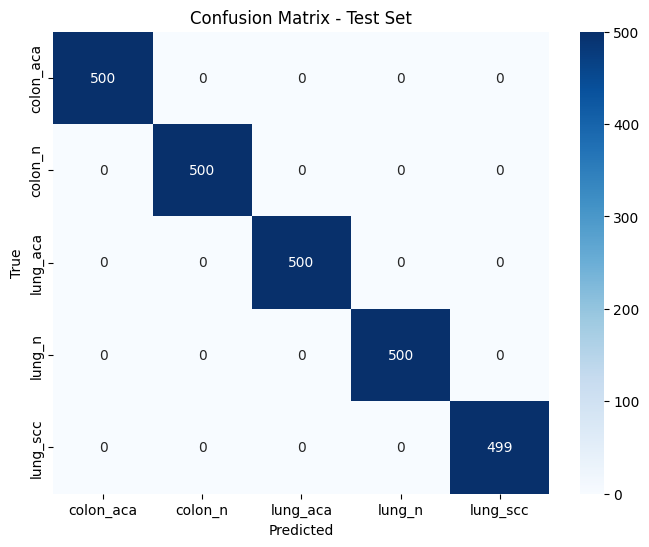

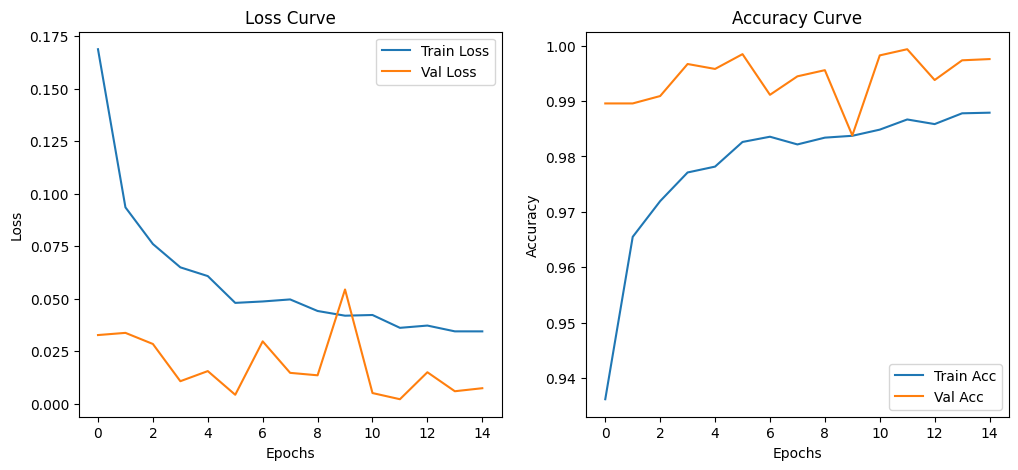

✅ Test Accuracy: 1.0
✅ Classification Report:
               precision    recall  f1-score   support

   colon_aca       1.00      1.00      1.00       500
     colon_n       1.00      1.00      1.00       500
    lung_aca       1.00      1.00      1.00       500
      lung_n       1.00      1.00      1.00       500
    lung_scc       1.00      1.00      1.00       499

    accuracy                           1.00      2499
   macro avg       1.00      1.00      1.00      2499
weighted avg       1.00      1.00      1.00      2499



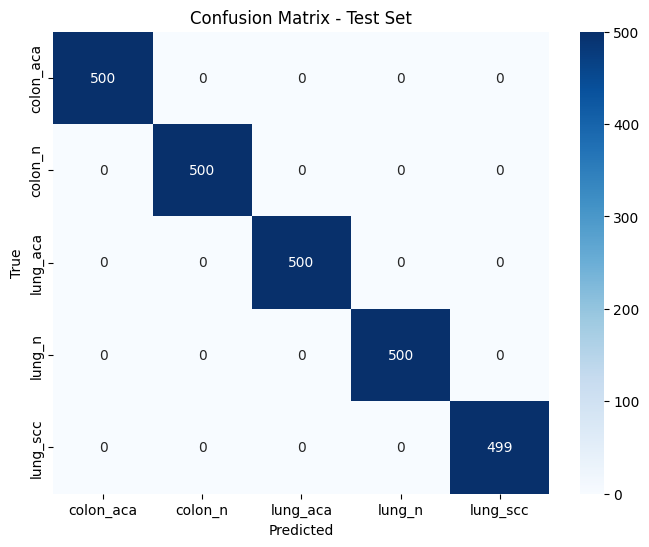

In [10]:
# Step 12: Plot Training Curves
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Val Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss Curve")
plt.savefig("loss_curve on Restnet18.png")

plt.subplot(1, 2, 2)
plt.plot(history["train_acc"], label="Train Acc")
plt.plot(history["val_acc"], label="Val Acc")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Accuracy Curve")

plt.savefig("training_curves on Restnet18.png")
plt.show()

# Step 13: Test Evaluation (using best model)
model.load_state_dict(torch.load("best_model.pth"))
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print("✅ Test Accuracy:", accuracy_score(all_labels, all_preds))
print("✅ Classification Report:\n", classification_report(all_labels, all_preds, target_names=le.classes_))

# Step 14: Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=le.classes_, yticklabels=le.classes_, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - Test Set")
plt.savefig("confusion_matrix on Restnet18.png")
plt.show()

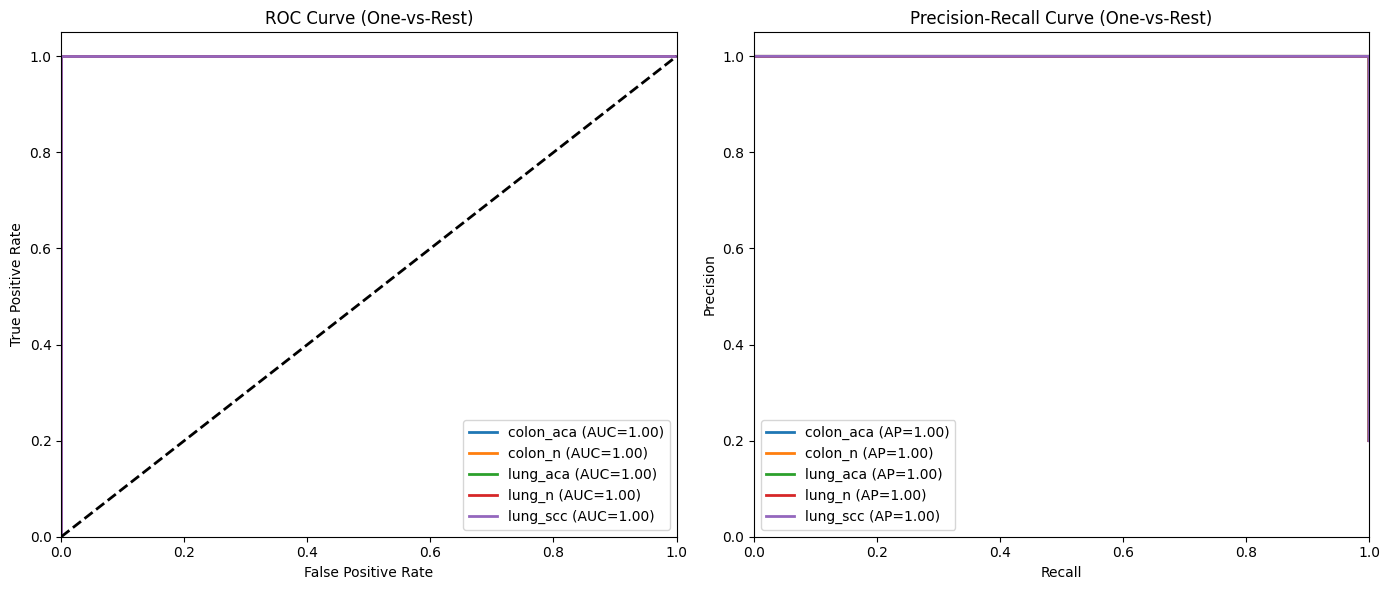

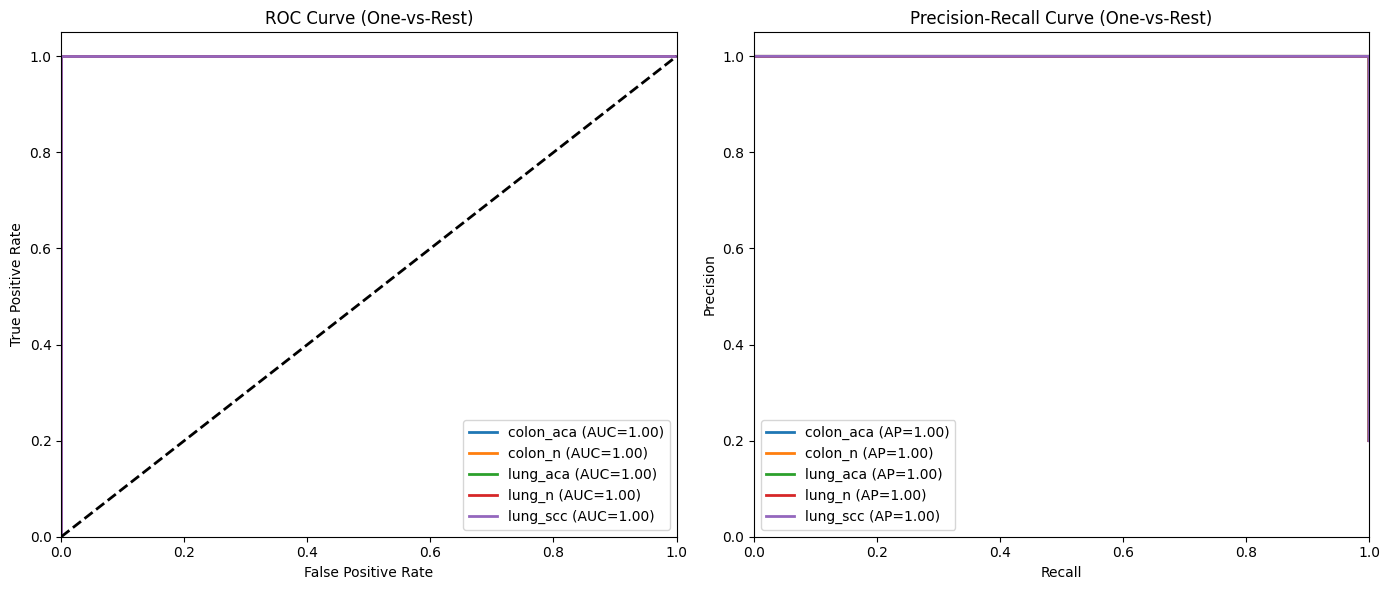

In [11]:
from sklearn.metrics import roc_curve, auc, roc_auc_score, precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize

# Binarize labels for multi-class ROC/PR
n_classes = len(classes)
y_true_bin = label_binarize(all_labels, classes=np.arange(n_classes))

# Get probability scores from model
y_score = []
model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        y_score.extend(probs.cpu().numpy())
y_score = np.array(y_score)

# Initialize plots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ---- ROC Curve ----
for i, class_name in enumerate(le.classes_):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, lw=2, label=f"{class_name} (AUC={roc_auc:.2f})")

axes[0].plot([0, 1], [0, 1], "k--", lw=2)
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve (One-vs-Rest)")
axes[0].legend(loc="lower right")

# ---- Precision-Recall Curve ----
for i, class_name in enumerate(le.classes_):
    precision, recall, _ = precision_recall_curve(y_true_bin[:, i], y_score[:, i])
    ap = average_precision_score(y_true_bin[:, i], y_score[:, i])
    axes[1].plot(recall, precision, lw=2, label=f"{class_name} (AP={ap:.2f})")

axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve (One-vs-Rest)")
axes[1].legend(loc="lower left")

# Adjust layout & save
plt.tight_layout()
plt.savefig("roc_pr_curves.png", dpi=300)  # ✅ Save at 300 dpi
plt.show()


In [12]:
import torch
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, cohen_kappa_score, matthews_corrcoef, balanced_accuracy_score

# -------- Evaluation Function --------
def evaluate_model(model, dataloader, device, name="Dataset"):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    # Convert to numpy arrays
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # Compute metrics
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    kappa = cohen_kappa_score(y_true, y_pred)
    mcc = matthews_corrcoef(y_true, y_pred)
    bal_acc = balanced_accuracy_score(y_true, y_pred)

    print(f"\n📊 {name} Metrics:")
    print(f"Accuracy:           {acc:.4f}")
    print(f"Precision:          {prec:.4f}")
    print(f"Recall:             {rec:.4f}")
    print(f"F1 Score:           {f1:.4f}")
    print(f"Cohen’s Kappa:      {kappa:.4f}")
    print(f"MCC:                {mcc:.4f}")
    print(f"Balanced Accuracy:  {bal_acc:.4f}")

    return {
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1": f1,
        "kappa": kappa,
        "mcc": mcc,
        "balanced_accuracy": bal_acc
    }

# -------- Call evaluation on each dataset --------
train_metrics = evaluate_model(model, train_loader, device, name="Train")
val_metrics   = evaluate_model(model, val_loader, device, name="Validation")
test_metrics  = evaluate_model(model, test_loader, device, name="Test")



📊 Train Metrics:
Accuracy:           0.9929
Precision:          0.9930
Recall:             0.9929
F1 Score:           0.9929
Cohen’s Kappa:      0.9912
MCC:                0.9912
Balanced Accuracy:  0.9929

📊 Validation Metrics:
Accuracy:           0.9993
Precision:          0.9993
Recall:             0.9993
F1 Score:           0.9993
Cohen’s Kappa:      0.9992
MCC:                0.9992
Balanced Accuracy:  0.9993

📊 Test Metrics:
Accuracy:           1.0000
Precision:          1.0000
Recall:             1.0000
F1 Score:           1.0000
Cohen’s Kappa:      1.0000
MCC:                1.0000
Balanced Accuracy:  1.0000


In [15]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, cohen_kappa_score, matthews_corrcoef, balanced_accuracy_score
import numpy as np
import matplotlib.pyplot as plt

# --- Metric Function ---
def compute_metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    kappa = cohen_kappa_score(y_true, y_pred)
    mcc = matthews_corrcoef(y_true, y_pred)
    bal_acc = balanced_accuracy_score(y_true, y_pred)
    return acc, prec, rec, f1, kappa, mcc, bal_acc


# --- Training Loop with Metrics ---
def train_model(model, train_loader, val_loader, device, num_epochs=20, lr=1e-4):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    history = {"train_loss": [], "val_loss": [],
               "train_acc": [], "val_acc": [],
               "train_prec": [], "val_prec": [],
               "train_rec": [], "val_rec": [],
               "train_f1": [], "val_f1": [],
               "train_kappa": [], "val_kappa": [],
               "train_mcc": [], "val_mcc": [],
               "train_bal_acc": [], "val_bal_acc": []}

    best_val_acc = 0.0

    for epoch in range(num_epochs):
        # --- TRAIN ---
        model.train()
        train_loss, y_true_train, y_pred_train = 0.0, [], []
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            _, preds = torch.max(outputs, 1)
            y_true_train.extend(labels.cpu().numpy())
            y_pred_train.extend(preds.cpu().numpy())

        # Metrics
        train_loss /= len(train_loader)
        train_acc, train_prec, train_rec, train_f1, train_kappa, train_mcc, train_bal_acc = compute_metrics(y_true_train, y_pred_train)

        # --- VALIDATION ---
        model.eval()
        val_loss, y_true_val, y_pred_val = 0.0, [], []
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                val_loss += loss.item()
                _, preds = torch.max(outputs, 1)
                y_true_val.extend(labels.cpu().numpy())
                y_pred_val.extend(preds.cpu().numpy())

        val_loss /= len(val_loader)
        val_acc, val_prec, val_rec, val_f1, val_kappa, val_mcc, val_bal_acc = compute_metrics(y_true_val, y_pred_val)

        # Save best model
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), "best_model.pth")

        # Store history
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["train_prec"].append(train_prec)
        history["val_prec"].append(val_prec)
        history["train_rec"].append(train_rec)
        history["val_rec"].append(val_rec)
        history["train_f1"].append(train_f1)
        history["val_f1"].append(val_f1)
        history["train_kappa"].append(train_kappa)
        history["val_kappa"].append(val_kappa)
        history["train_mcc"].append(train_mcc)
        history["val_mcc"].append(val_mcc)
        history["train_bal_acc"].append(train_bal_acc)
        history["val_bal_acc"].append(val_bal_acc)

        print(f"Epoch {epoch+1}/{num_epochs} "
              f"| Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f} "
              f"| Train F1: {train_f1:.4f}, Val F1: {val_f1:.4f}")

    return history


# --- Plot Loss & Accuracy ---
def plot_training_curves(history):
    plt.figure(figsize=(12,5))

    # Loss
    plt.subplot(1,2,1)
    plt.plot(history["train_loss"], label="Train Loss")
    plt.plot(history["val_loss"], label="Val Loss")
    plt.xlabel("Epochs"); plt.ylabel("Loss"); plt.title("Loss per Epoch")
    plt.legend()

    # Accuracy
    plt.subplot(1,2,2)
    plt.plot(history["train_acc"], label="Train Acc")
    plt.plot(history["val_acc"], label="Val Acc")
    plt.xlabel("Epochs"); plt.ylabel("Accuracy"); plt.title("Accuracy per Epoch")
    plt.legend()

    plt.tight_layout()
    plt.savefig("training_curves.png", dpi=300)
    plt.show()


##Restnet50


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 138MB/s]
Epoch 1/10 [Val]: 100%|██████████| 282/282 [00:54<00:00,  5.21it/s]


Epoch 1/10 | Train Acc: 0.9346, Val Acc: 0.9887 | Train F1: 0.9346, Val F1: 0.9887


Epoch 2/10 [Val]: 100%|██████████| 282/282 [00:52<00:00,  5.37it/s]


Epoch 2/10 | Train Acc: 0.9659, Val Acc: 0.9909 | Train F1: 0.9659, Val F1: 0.9909


... (12 outputs left out)

Epoch 9/10 [Val]: 100%|██████████| 282/282 [00:56<00:00,  5.03it/s]


Epoch 9/10 | Train Acc: 0.9834, Val Acc: 0.9973 | Train F1: 0.9834, Val F1: 0.9973


Epoch 10/10 [Val]: 100%|██████████| 282/282 [00:53<00:00,  5.30it/s]


Epoch 10/10 | Train Acc: 0.9853, Val Acc: 0.9973 | Train F1: 0.9853, Val F1: 0.9973


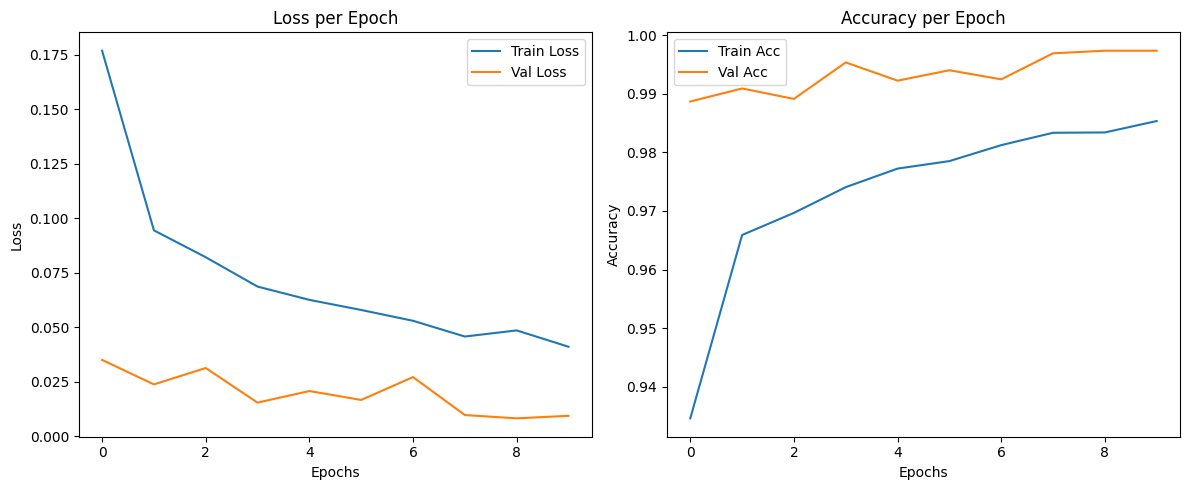


📊 Test Metrics:
Accuracy: 0.9988
Precision: 0.9988
Recall: 0.9988
F1 Score: 0.9988
Cohen Kappa: 0.9985
MCC: 0.9985
Balanced Accuracy: 0.9988


In [17]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, cohen_kappa_score, matthews_corrcoef, balanced_accuracy_score
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ----- Load ResNet50 -----
model = models.resnet50(pretrained=True)

# Replace the final layer for our 5 classes
num_classes = len(classes)
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

# ----- Metric Function -----
def compute_metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    kappa = cohen_kappa_score(y_true, y_pred)
    mcc = matthews_corrcoef(y_true, y_pred)
    bal_acc = balanced_accuracy_score(y_true, y_pred)
    return acc, prec, rec, f1, kappa, mcc, bal_acc

# ----- Training Loop -----
num_epochs = 10
history = {
    "train_loss": [], "val_loss": [],
    "train_acc": [], "val_acc": [],
    "train_prec": [], "val_prec": [],
    "train_rec": [], "val_rec": [],
    "train_f1": [], "val_f1": [],
    "train_kappa": [], "val_kappa": [],
    "train_mcc": [], "val_mcc": [],
    "train_bal_acc": [], "val_bal_acc": []
}

best_val_acc = 0.0

for epoch in range(num_epochs):
    # ---- Train ----
    model.train()
    train_loss, y_true_train, y_pred_train = 0.0, [], []
    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]"):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        preds = torch.argmax(outputs, dim=1)
        y_true_train.extend(labels.cpu().numpy())
        y_pred_train.extend(preds.cpu().numpy())

    train_loss /= len(train_loader)
    train_acc, train_prec, train_rec, train_f1, train_kappa, train_mcc, train_bal_acc = compute_metrics(y_true_train, y_pred_train)

    # ---- Validation ----
    model.eval()
    val_loss, y_true_val, y_pred_val = 0.0, [], []
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Val]"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()
            preds = torch.argmax(outputs, dim=1)
            y_true_val.extend(labels.cpu().numpy())
            y_pred_val.extend(preds.cpu().numpy())

    val_loss /= len(val_loader)
    val_acc, val_prec, val_rec, val_f1, val_kappa, val_mcc, val_bal_acc = compute_metrics(y_true_val, y_pred_val)

    # ---- Save Best Model ----
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_resnet50_model.pth")

    # ---- Store history ----
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["train_prec"].append(train_prec)
    history["val_prec"].append(val_prec)
    history["train_rec"].append(train_rec)
    history["val_rec"].append(val_rec)
    history["train_f1"].append(train_f1)
    history["val_f1"].append(val_f1)
    history["train_kappa"].append(train_kappa)
    history["val_kappa"].append(val_kappa)
    history["train_mcc"].append(train_mcc)
    history["val_mcc"].append(val_mcc)
    history["train_bal_acc"].append(train_bal_acc)
    history["val_bal_acc"].append(val_bal_acc)

    print(f"Epoch {epoch+1}/{num_epochs} | Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f} | Train F1: {train_f1:.4f}, Val F1: {val_f1:.4f}")

# ----- Plot Loss & Accuracy -----
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Val Loss")
plt.xlabel("Epochs"); plt.ylabel("Loss"); plt.title("Loss per Epoch")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history["train_acc"], label="Train Acc")
plt.plot(history["val_acc"], label="Val Acc")
plt.xlabel("Epochs"); plt.ylabel("Accuracy"); plt.title("Accuracy per Epoch")
plt.legend()
plt.tight_layout()
plt.savefig("resnet50_training_curves.png", dpi=300)
plt.show()

# ----- Evaluate on Test Set -----
model.load_state_dict(torch.load("best_resnet50_model.pth"))
model.eval()
y_true_test, y_pred_test = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        preds = torch.argmax(outputs, dim=1)
        y_true_test.extend(labels.cpu().numpy())
        y_pred_test.extend(preds.cpu().numpy())

test_acc, test_prec, test_rec, test_f1, test_kappa, test_mcc, test_bal_acc = compute_metrics(y_true_test, y_pred_test)

print("\n📊 Test Metrics:")
print(f"Accuracy: {test_acc:.4f}")
print(f"Precision: {test_prec:.4f}")
print(f"Recall: {test_rec:.4f}")
print(f"F1 Score: {test_f1:.4f}")
print(f"Cohen Kappa: {test_kappa:.4f}")
print(f"MCC: {test_mcc:.4f}")
print(f"Balanced Accuracy: {test_bal_acc:.4f}")


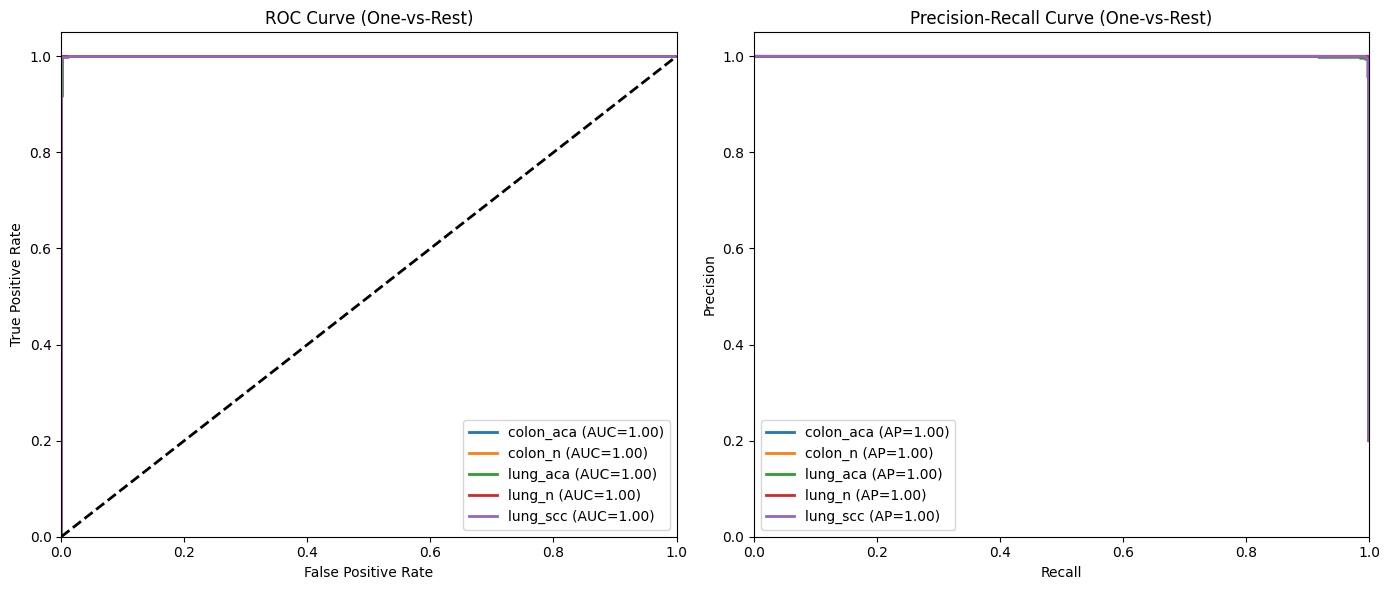

In [18]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt
import numpy as np
import torch

# ---- Binarize Test Labels ----
y_true_bin = label_binarize(y_true_test, classes=np.arange(len(classes)))

# ---- Get Probabilities from Model ----
y_score = []
model.eval()
with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        y_score.extend(probs.cpu().numpy())

y_score = np.array(y_score)

# ---- Plot ROC & PR Curves Side by Side ----
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- ROC Curves ---
for i, class_name in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, lw=2, label=f"{class_name} (AUC={roc_auc:.2f})")

axes[0].plot([0, 1], [0, 1], "k--", lw=2)
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve (One-vs-Rest)")
axes[0].legend(loc="lower right")

# --- Precision-Recall Curves ---
for i, class_name in enumerate(classes):
    precision, recall, _ = precision_recall_curve(y_true_bin[:, i], y_score[:, i])
    ap = average_precision_score(y_true_bin[:, i], y_score[:, i])
    axes[1].plot(recall, precision, lw=2, label=f"{class_name} (AP={ap:.2f})")

axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve (One-vs-Rest)")
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.savefig("resnet50_roc_pr_curves.png", dpi=300)  # ✅ Save at 300 dpi
plt.show()


In [19]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, cohen_kappa_score, matthews_corrcoef, balanced_accuracy_score
import numpy as np
import torch

# --- Function to evaluate a DataLoader ---
def evaluate_model(model, dataloader, device, dataset_name="Dataset"):
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            preds = torch.argmax(outputs, dim=1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # Compute metrics
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    kappa = cohen_kappa_score(y_true, y_pred)
    mcc = matthews_corrcoef(y_true, y_pred)
    bal_acc = balanced_accuracy_score(y_true, y_pred)

    print(f"\n📊 {dataset_name} Metrics:")
    print(f"Accuracy:           {acc:.4f}")
    print(f"Precision:          {prec:.4f}")
    print(f"Recall:             {rec:.4f}")
    print(f"F1 Score:           {f1:.4f}")
    print(f"Cohen’s Kappa:      {kappa:.4f}")
    print(f"MCC:                {mcc:.4f}")
    print(f"Balanced Accuracy:  {bal_acc:.4f}")

    return {
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1": f1,
        "kappa": kappa,
        "mcc": mcc,
        "balanced_accuracy": bal_acc
    }

# --- Evaluate Train, Validation, Test ---
train_metrics = evaluate_model(model, train_loader, device, "Train")
val_metrics   = evaluate_model(model, val_loader, device, "Validation")
test_metrics  = evaluate_model(model, test_loader, device, "Test")



📊 Train Metrics:
Accuracy:           0.9901
Precision:          0.9901
Recall:             0.9901
F1 Score:           0.9901
Cohen’s Kappa:      0.9876
MCC:                0.9876
Balanced Accuracy:  0.9901

📊 Validation Metrics:
Accuracy:           0.9973
Precision:          0.9974
Recall:             0.9973
F1 Score:           0.9973
Cohen’s Kappa:      0.9967
MCC:                0.9967
Balanced Accuracy:  0.9973

📊 Test Metrics:
Accuracy:           0.9988
Precision:          0.9988
Recall:             0.9988
F1 Score:           0.9988
Cohen’s Kappa:      0.9985
MCC:                0.9985
Balanced Accuracy:  0.9988
